## Corrélation

Ce notebook vous présente une méthode pour comparer la corrélation entre 2 séries temporelles. L'idée ici est de déterminer si une source de données peut nous aider à prédire la valeur d'une valeur mobilière particulière. Par exemple, il serait intéressant de vérifier si le coin ada varie en fonction du bitcoin ou bien de l'ethereum, ou encore de valeurs boursières.

Ce notebook a été construit à partir de la source suivante : [*Practical Time Series Analysis, Prediction with Statistics & Machine Learning*, Aileen Nielsen, 2020](https://www.oreilly.com/library/view/practical-time-series/9781492041641/).

Dans ce notebook, nous allons :
1. charger les données de 2 série temporelles, ada et btc
2. sélectionner les plages temporelles sur laquelle comparer les données
2. afficher les données via un nuage de points
3. afficher les données via leur différence
4. décaler la valeur du btc de 1 pour tester sa prédiction sur l'ada

In [6]:
%run -i "../Loader.ipynb"
plt.rcParams['figure.figsize'] = [15, 8]

### Sélection de la plage temporelle maximale

Afin de calculer la corrélation entre les deux valeurs mobilières, on commence par charger les données sur un intervalle de temps commun.


In [7]:
loader = Loader(dataDefaultPath="..", debug=False)

loader.loadSource(Loader.COINCODEX, forceEqualDate=True)

dfAda = loader.get(Loader.COINCODEX, Loader.ADA)
dfBtc = loader.get(Loader.COINCODEX, Loader.BTC)

print("dfAda index:", dfAda.index.min(), " ", dfAda.index.max())
print("dfBtc index:", dfBtc.index.min(), " ", dfBtc.index.max())

init loader: .. False
-----------------
path ===== ..\data\Coincodex\coin_Cardano.csv  &  ..
path ===== ..\data\Coincodex\coin_Aave.csv  &  ..
path ===== ..\data\Coincodex\coin_Bitcoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Cosmos.csv  &  ..
path ===== ..\data\Coincodex\coin_Dogecoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Ethereum.csv  &  ..
path ===== ..\data\Coincodex\coin_Litecoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Monero.csv  &  ..
path ===== ..\data\Coincodex\coin_Polkadot.csv  &  ..
path ===== ..\data\Coincodex\coin_USDCoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Microsoft.csv  &  ..
path ===== ..\data\Coincodex\coin_AT&T.csv  &  ..
path ===== ..\data\Coincodex\coin_cac40.csv  &  ..
path ===== ..\data\Coincodex\coin_Amazon.csv  &  ..
path ===== ..\data\Coincodex\coin_Tesla.csv  &  ..
dfAda index: 2017-10-01   2022-10-23
dfBtc index: 2017-10-01   2022-10-23


### Corrélation des données brutes

La première méthode consisterait à afficher les couples des valeurs des deux coins via un nuage de points, et de calculer la corrélation entre les deux ensembles de valeurs.

Correlation : 0.8874225674186862


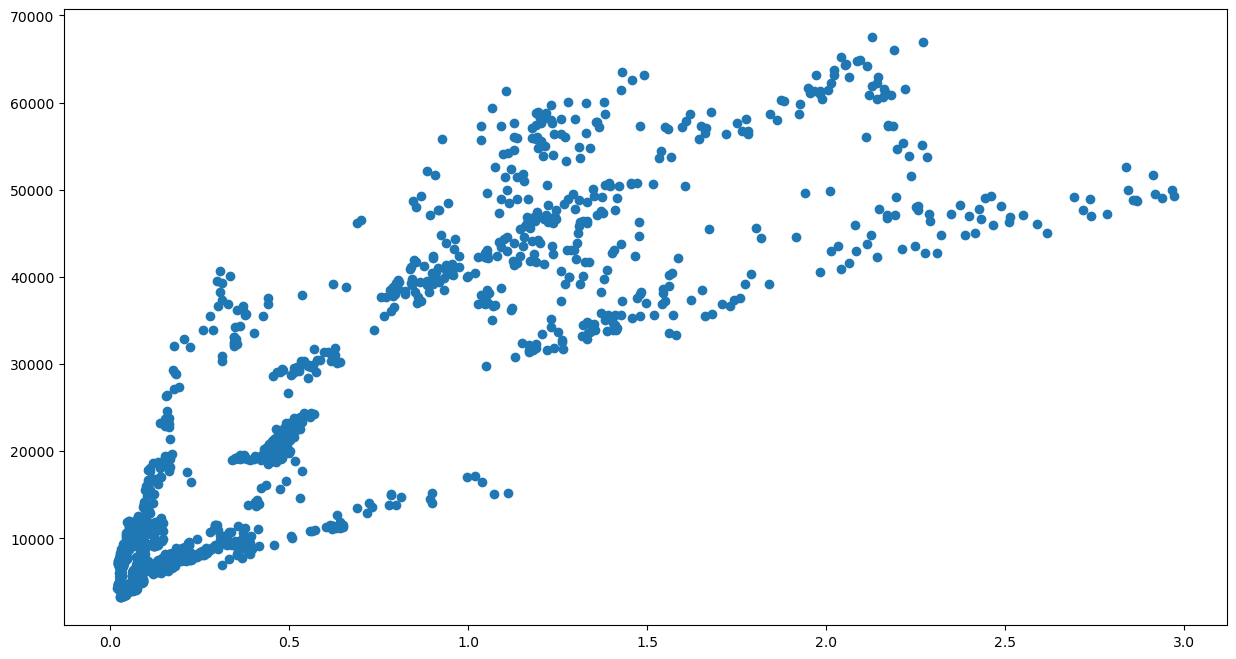

In [8]:
plt.scatter(x=dfAda.Close, y=dfBtc.Close)

print("Correlation :", dfAda.Close.corr(dfBtc.Close))

Interprétation de cette figure : 
- un point (x,y) est la valeur du `ada` et du `btc` sur une même date (en X, `ada` et en Y, `btc`)
- on voit que la figure qu'un `ada` élevé est lié à un `btc` élevé
- on pourrait résumer ces points en une droite partant de (0,0) pour aller en (2.5, 5000)
- on a une corrélation positive : quand l'`ada` monte, le `btc` monte aussi !
 
Il semblerait donc que nous ayons une forte corrélation entre les 2 coins. Afin de vérifier cette hypothèse, nous allons étudier les variations de ces deux séries temporelles, via leur différence 2 à 2.

### Corrélation de la différence

Nous réalisons le même test que précédemment, mais sur les différences de ces séries.

Correlation : 0.5677676467851012


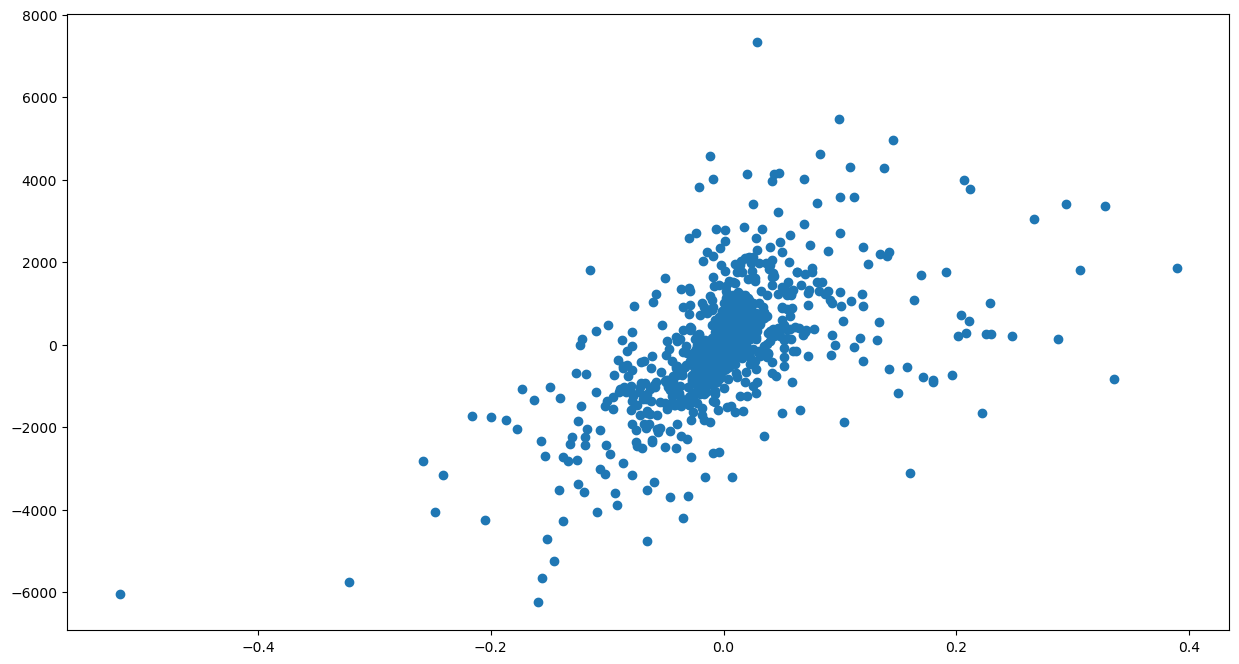

In [9]:
plt.scatter(x=dfAda.Close.diff(), y=dfBtc.Close.diff())

print("Correlation :", dfAda.Close.diff().corr(dfBtc.Close.diff()))

Nous notons que la corrélation a fortement baissée (il est plus difficile de tracer une droite représentant ces données), mais une corrélation est toujours présente. Et il nous reste un problème à régler : si nous voulons utiliser la prédiction du `btc` pour prédire l'`ada`, il faut utiliser le prix du `btc` un jour avant. 

Nous devons donc étudier la corrélation entre le `btc` décaler d'un jour en moins et l'`ada`.

### Corrélation de la différence en décalant le Bitcoin de 1 jour en arrière

Pour décaler une série temporelle d'une "case" en arière, il faut utiliser la fonction `shift(-1)`, applicable sur une `DataFrame`.



In [10]:
dfBtc.shift(-1).head()

,High,Low,Open,Close,Volume,Marketcap
Date,,,,,,
2017-10-01,4466.306182,4237.159335,4378.062350,4311.980091,1.146607e+09,7.206486e+10
2017-10-02,4337.574576,4206.295821,4312.216362,4235.080828,9.741398e+08,7.085208e+10
2017-10-03,4348.467992,4157.650335,4237.438692,4311.095697,9.920291e+08,7.063711e+10
2017-10-04,4392.401416,4296.675659,4308.291188,4349.048323,9.624500e+08,7.249673e+10
2017-10-05,4416.203923,4312.669461,4347.018631,4401.216587,7.810308e+08,7.245000e+10


Correlation : -0.048734939084590936


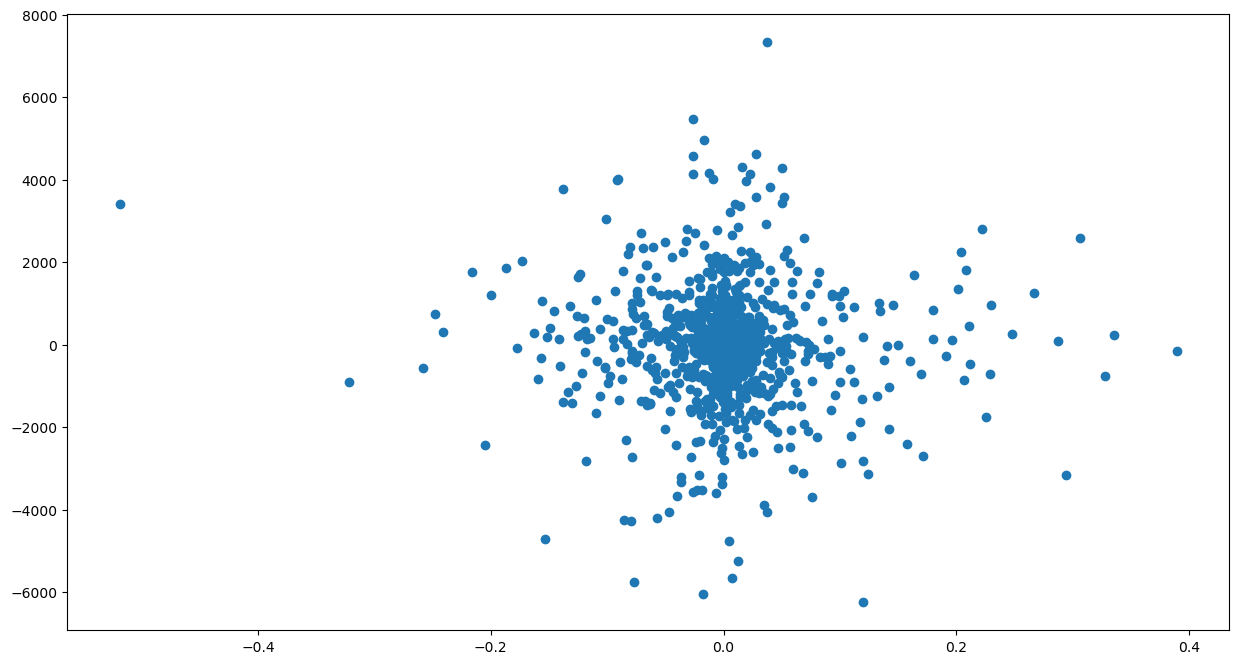

In [12]:
plt.scatter(x=dfAda.Close.diff(), y=dfBtc.Close.shift(-1).diff())

print("Correlation :", dfAda.Close.diff().corr(dfBtc.shift(-1).Close.diff()))

La corrélation semble maintenant quasi nulle...on observe ici un nuage de point que l'on pourrait résumer avec un cercle.

### Conclusion

Parfait. Vous savez maintenant étudier la corrélation entre deux valeurs mobilières. 

**Question(s)**:
1. récupérer des données d'actions (CAC40, Total, des monnaies, ...)
2. tester la corrélation entre ces données et le `btc`